In [33]:
import pandas as pd
import numbers as np



In [34]:
df = pd.read_csv("D:\\projects\\creditcard_fraud\\notebooks\\data\\creditcard_1.csv")

In [35]:
X = df.drop(columns="Class")
y = df["Class"]

## Time-Based Split (80/20)

In [36]:
split_idx = int(len(df) * 0.8)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

In [37]:
print(X_train.shape)
print(X_test.shape)

(227845, 30)
(56962, 30)


In [38]:
from sklearn.dummy import DummyClassifier

dummy = DummyClassifier(strategy="most_frequent")

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test)
dummy_score = dummy.predict_proba(X_test)[:, 1]

In [39]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
)

print("Precision:", precision_score(y_test, dummy_pred, zero_division=0))
print("Recall:", recall_score(y_test, dummy_pred))
print("F1:", f1_score(y_test, dummy_pred))
print("Average Precision:", average_precision_score(y_test, dummy_score))

Precision: 0.0
Recall: 0.0
F1: 0.0
Average Precision: 0.001316667251852112


In [40]:
cm_dummy = confusion_matrix(y_test, dummy_pred)

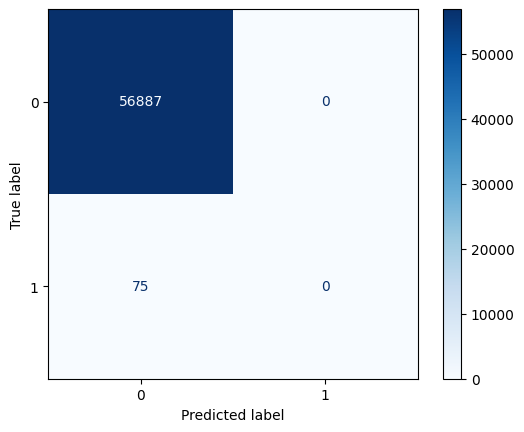

In [41]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(cm_dummy).plot(cmap="Blues")

plt.savefig(
    "../reports/baselines/dummy_confusion_matrix.png",
    dpi=300
)

plt.show()

In [42]:
from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression(max_iter=100)

logreg.fit(X_train, y_train)

C:\Users\Abhishek Goswami\AppData\Roaming\Python\Python310\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [43]:
log_pred = logreg.predict(X_test)

log_prob = logreg.predict_proba(X_test)[:, 1]

In [44]:
print("Precision:", precision_score(y_test, log_pred))
print("Recall:", recall_score(y_test, log_pred))
print("F1:", f1_score(y_test, log_pred))
print("Average Precision:", average_precision_score(y_test, log_prob))

Precision: 0.9032258064516129
Recall: 0.37333333333333335
F1: 0.5283018867924528
Average Precision: 0.67264568127437


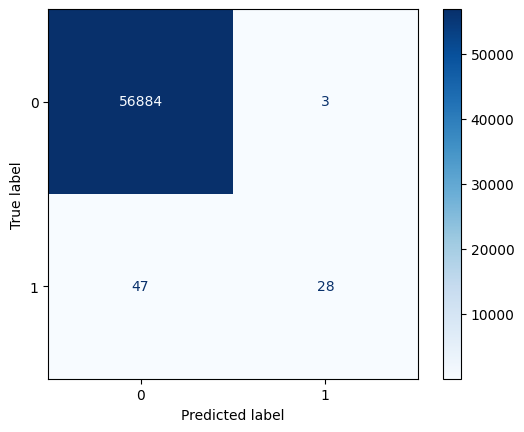

In [45]:
cm = confusion_matrix(y_test, log_pred)

ConfusionMatrixDisplay(cm).plot(cmap="Blues")

plt.savefig(
    "../reports/baselines/logistic_confusion_matrix.png",
    dpi=300
)

plt.show()

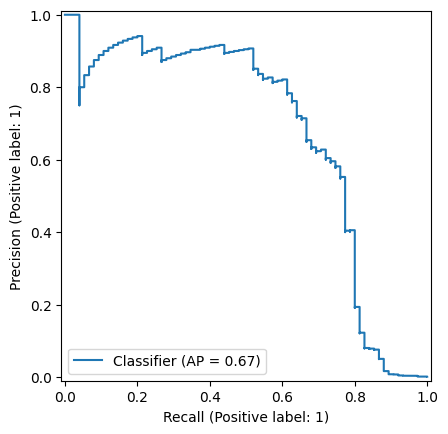

In [46]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    log_prob
)

plt.savefig(
    "../reports/baselines/precision_recall_curve.png",
    dpi=300
)

plt.show()